In [1]:
import json
import numpy as np
import matplotlib.pyplot as plt

with open("metrics_fe.json") as f:
    fe = json.load(f)

with open("metrics_ft.json") as f:
    ft = json.load(f)

In [2]:
# Itsetehdyn CNN:n sekaannusmatriisi
cnn_cm = np.array([
    [61, 0, 0, 0, 0, 0],
    [3, 58, 9, 0, 0, 0],
    [0, 0, 64, 8, 0, 0],
    [0, 0, 1, 78, 2, 0],
    [0, 0, 1, 7, 37, 5],
    [0, 0, 0, 0, 2, 67]
])

models = {
    "CNN": cnn_cm,
    "VGG16 FE": np.array(fe["confusion_matrix"]),
    "VGG16 FT": np.array(ft["confusion_matrix"])
}

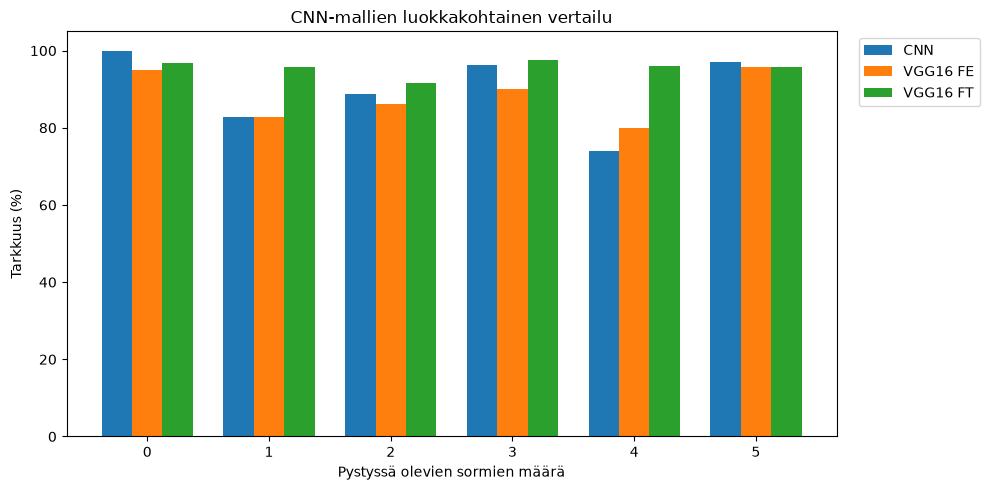

In [3]:
# 1. Luokkakohtainen vertailu
fig, ax = plt.subplots(figsize=(10, 5))
x = np.arange(6)
width = 0.25

for i, (name, cm) in enumerate(models.items()):
    accuracy = 100 * np.diag(cm) / cm.sum(axis=1)
    ax.bar(x + (i - 1) * width, accuracy,
           width, label=name)

ax.set_xticks(x)
ax.set_xticklabels(range(6))
ax.set_xlabel("Pystyssä olevien sormien määrä")
ax.set_ylabel("Tarkkuus (%)")
ax.set_ylim(0, 105)
ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1))
ax.set_title("CNN-mallien luokkakohtainen vertailu")
plt.tight_layout()
plt.show()

## Mallien vertailun päätelmät

Kokonaisuutena VGG16 Fine Tuning -malli suoriutui tarkimmin. VGG16 FT -malli sai hieman heikomman tarkkuuden luokissa 0 ja 5 sormea pystyssä, mutta muissa luokissa se ennusti paremmin kuin oma CNN-malli.

Oma CNN-malli sai lopulliseksi testitarkkuudeksi 90,57 %, kun VGG16 FT -malli saavutti 95,53 % tarkkuuden. Mallien välinen ero oli siis noin 5 prosenttiyksikköä, joten ne suoriutuivat melko lähellä toisiaan. VGG16 Feature Extraction -mallin testitarkkuus oli 88,59 %, eli se jäi molemmista malleista.

Suurin ero oli neljän sormen luokassa, jossa oma CNN-malli saavutti 74 % tarkkuuden ja VGG16 FT -malli 96 %. Ero oli siis 22 prosenttiyksikköä. CNN-malli sekoitti neljän sormen kuvia erityisesti kolmen ja viiden sormen luokkiin. Syy voi olla datassa, joita ylläolevissa kuvissa havaitaan. Kuviin on päässyt epätarkkoja kuvia missä sormien liike on tallentunut kuvaan. Silmämääräsesti niin sanotut liikkuvat sormet eli haamusormet eivät ole suuria ja niiden havaitsemiseen esikoulutettu VGG16 malli irroitti piirteet tarkemmin.

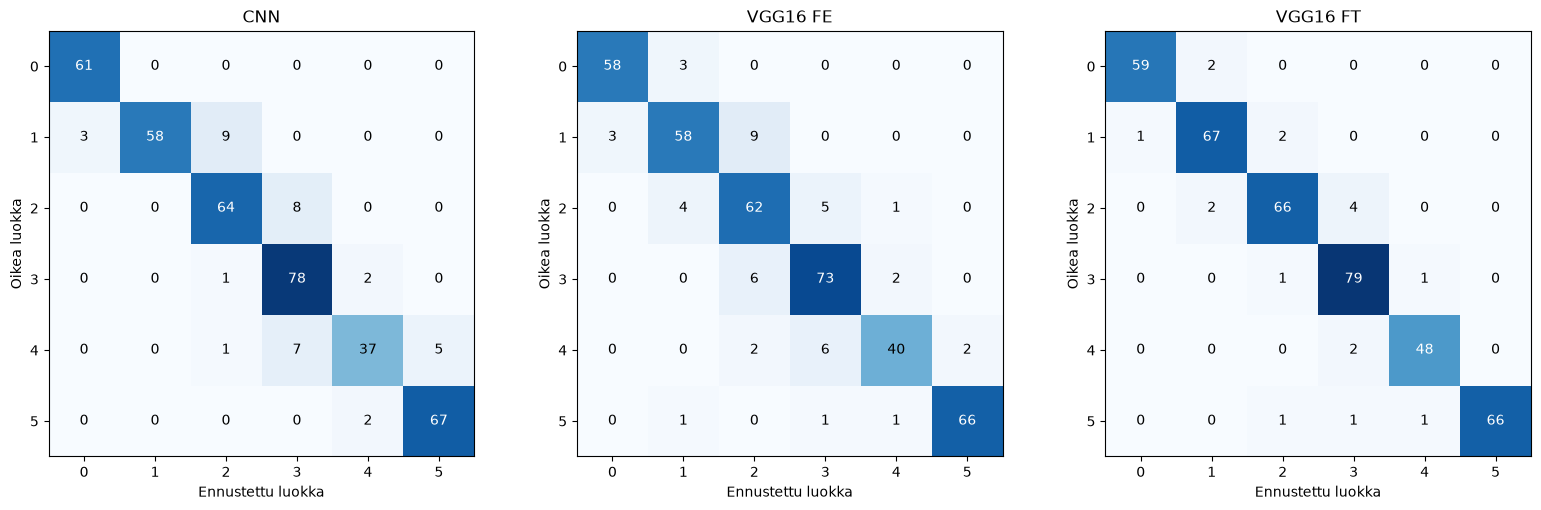

In [4]:
# 2. Kolme sekaannusmatriisia rinnakkain
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, (name, cm) in zip(axes, models.items()):
    ax.imshow(cm, cmap="Blues", vmin=0, vmax=81)
    ax.set_title(name)
    ax.set_xlabel("Ennustettu luokka")
    ax.set_ylabel("Oikea luokka")
    ax.set_xticks(range(6))
    ax.set_yticks(range(6))

    for row in range(6):
        for col in range(6):
            ax.text(col, row, str(cm[row, col]),
                    ha="center", va="center",
                    color="white" if cm[row, col] > 40
                    else "black")

plt.tight_layout()
plt.show()


## Confusion matrixien johtopäätökset

Oma CNN-malli sekoitti selkeästi eniten vierekkäisiä luokkia keskenään. Esimerkiksi CNN sekoitti 8 kahden sormen kuvaa kolmen sormen luokkaan, 7 neljän sormen kuvaa kolmen sormen luokkaan ja 9 yhden sormen kuvaa kahden sormen luokkaan. Nämä sekaannukset vähenivät selkeästi VGG16 FT -mallissa. Oma CNN-malli sekoitti vain kerran sormien lukumäärän yli yhdellä, kun neljän sormen kuva ennustettiin kahdeksi sormeksi. Suurempia sormimäärän sekaannuksia oli siis vain yksi kappale, missä oma CNN suoriutui malleista parhaiten.

VGG16 FE -malli suoriutui heikoiten ja teki määrällisesti eniten virheitä. Sen näkee jo testituloksista, joissa tarkkuudeksi saatiin alhaisempi 88,59 %. FE-malli jäi 0, 2, 3 ja 5 sormen luokissa oman CNN-mallin tarkkuudesta. Mallin heikkous korostuu myös suuremmissa sormimäärän sekaannuksissa. Esimerkiksi viittä sormea ennustettiin yhdeksi ja kahden sormen heittoja oli yhteensä neljä kappaletta.

VGG16 FT -mallissa suurin sekaannus tapahtui kahden ja kolmen sormen luokkien välillä, kun neljä kahden sormen kuvaa ennustettiin kolmeksi sormeksi. Muuten sekaannukset olivat lähinnä yksittäistapauksia. Varmuutta ei ole ennen lisätarkastelua, mutta yksittäistapaukset saattavat johtua huonoista kuvista, joissa sormet esimerkiksi liikkuvat ja malli ei tunnista niiden piirteitä kunnolla. Tämä voisi selittää myös suuremmat sekaannukset, joissa viiden sormen kuva ennustettiin kahdeksi tai kolmeksi sormeksi. Näistä viiden sormen ennustaminen kahdeksi oli suurin yksittäinen virhe.

VGG16 FT -malli ennusti vähiten väärin ja hävisi omalle CNN-mallille vain 0 ja 5 sormen luokissa. Lopullinen testitarkkuus oli 4,96 prosenttiyksikköä parempi. Muutamia ohiheittoja olisi kuitenkin hyvä tarkastella tarkemmin. Mielenkiintoisinta olisi katsoa, miksi FT-malli ennusti viiden sormen kuvan kahdeksi sormeksi eli kolmen sormen heitolla, ja miksi VGG16 FE -malli ennusti viisi sormea yhdeksi sormeksi. Kuvat voivat olla myös samoja, jolloin olisi mielenkiintoista selvittää, miksi molemmat mallit tekevät samasta kuvasta näin suuren virheen.